## Lab Assignment 01

Step 1 - Loading the dataset

In [1]:
import pandas as pd

df = pd.read_csv('voice.csv')
df.columns = df.columns.str.strip()

print("Shape:", df.shape)
print("Columns:", df.columns.tolist())
print("\nClass counts:")
print(df["label"].value_counts())
print("\nMissing values:", df.isna().sum().sum())

Shape: (3168, 21)
Columns: ['meanfreq', 'sd', 'median', 'Q25', 'Q75', 'IQR', 'skew', 'kurt', 'sp.ent', 'sfm', 'mode', 'centroid', 'meanfun', 'minfun', 'maxfun', 'meandom', 'mindom', 'maxdom', 'dfrange', 'modindx', 'label']

Class counts:
label
male      1584
female    1584
Name: count, dtype: int64

Missing values: 0


Step 2 - Split into training and test data

In [2]:
from sklearn.model_selection import train_test_split

X = df.drop(columns="label")
y = df["label"].str.strip().str.lower()

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training rows:", len(X_train))
print("Test rows:", len(X_test))

Training rows: 2534
Test rows: 634


Step 3 - Find the best feature count and k

In [3]:
from sklearn.pipeline import Pipeline
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import GridSearchCV, StratifiedKFold

pipeline = Pipeline([
    ("select", SelectKBest(score_func=f_classif)),
    ("scale", StandardScaler()),
    ("knn", KNeighborsClassifier())
])

param_grid = {
    "select__k": list(range(1, X_train.shape[1] + 1)),
    "knn__n_neighbors": list(range(1, 32, 2))
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

grid = GridSearchCV(
    estimator=pipeline,
    param_grid=param_grid,
    scoring="accuracy",
    cv=cv,
    n_jobs=-1,
    refit=True
)

grid.fit(X_train, y_train)

print("Best cross-validation accuracy:", round(grid.best_score_, 4))
print("Best parameters:", grid.best_params_)

Best cross-validation accuracy: 0.9814
Best parameters: {'knn__n_neighbors': 3, 'select__k': 6}


Step 4 - Report the selected features and test performance

In [4]:
from sklearn.metrics import accuracy_score, classification_report

best_model = grid.best_estimator_
y_pred = best_model.predict(X_test)

selector = best_model.named_steps["select"]
selected_features = X_train.columns[selector.get_support()].tolist()

print("Selected features:", selected_features)
print("Best k:", grid.best_params_["knn__n_neighbors"])
print("Number of selected features:", grid.best_params_["select__k"])
print("Test accuracy:", round(accuracy_score(y_test, y_pred), 4))
print("\nClassification report:")
print(classification_report(y_test, y_pred))

Selected features: ['sd', 'Q25', 'IQR', 'sp.ent', 'sfm', 'meanfun']
Best k: 3
Number of selected features: 6
Test accuracy: 0.9874

Classification report:
              precision    recall  f1-score   support

      female       0.99      0.99      0.99       317
        male       0.99      0.99      0.99       317

    accuracy                           0.99       634
   macro avg       0.99      0.99      0.99       634
weighted avg       0.99      0.99      0.99       634



Step 5 - Graph: compare feature counts and k values

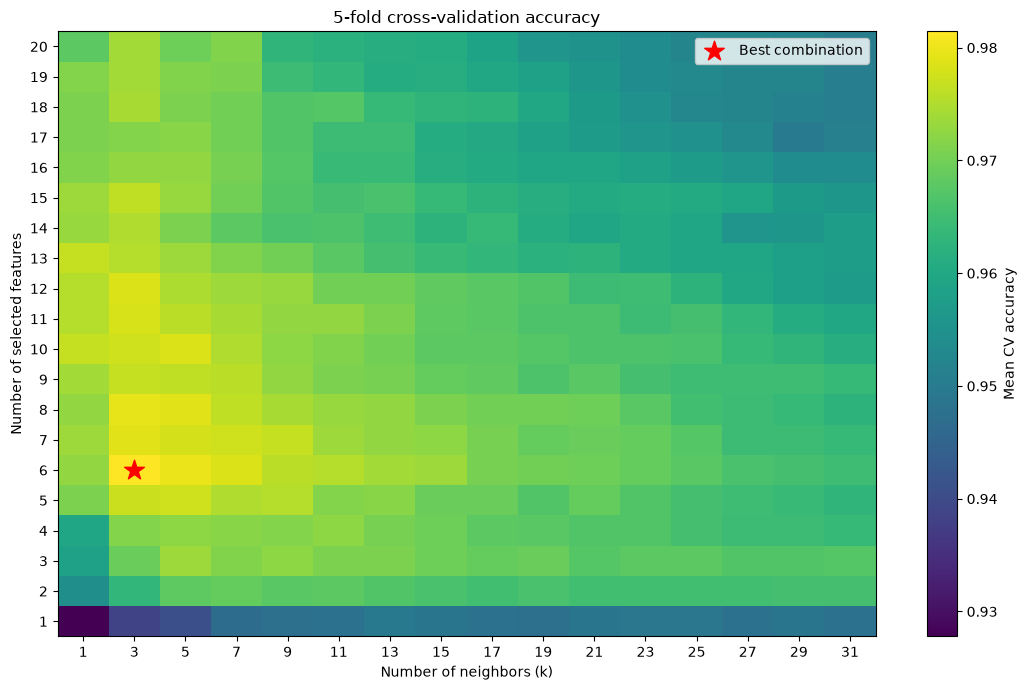

In [5]:
import matplotlib.pyplot as plt
import pandas as pd

results = pd.DataFrame(grid.cv_results_)
results["n_features"] = results["param_select__k"].astype(int)
results["neighbors"] = results["param_knn__n_neighbors"].astype(int)

heatmap_data = results.pivot(
    index="n_features",
    columns="neighbors",
    values="mean_test_score"
).sort_index()

best_n = grid.best_params_["select__k"]
best_k = grid.best_params_["knn__n_neighbors"]

fig, ax = plt.subplots(figsize=(11, 7))
im = ax.imshow(heatmap_data.values, aspect="auto", origin="lower", cmap="viridis")

ax.set_xticks(range(len(heatmap_data.columns)))
ax.set_xticklabels(heatmap_data.columns)
ax.set_yticks(range(len(heatmap_data.index)))
ax.set_yticklabels(heatmap_data.index)
ax.set_xlabel("Number of neighbors (k)")
ax.set_ylabel("Number of selected features")
ax.set_title("5-fold cross-validation accuracy")

best_x = list(heatmap_data.columns).index(best_k)
best_y = list(heatmap_data.index).index(best_n)
ax.scatter(best_x, best_y, marker="*", s=220, color="red", label="Best combination")
ax.legend()

fig.colorbar(im, ax=ax, label="Mean CV accuracy")
plt.tight_layout()
plt.show()

Step 6 - Graph: show which features were selected

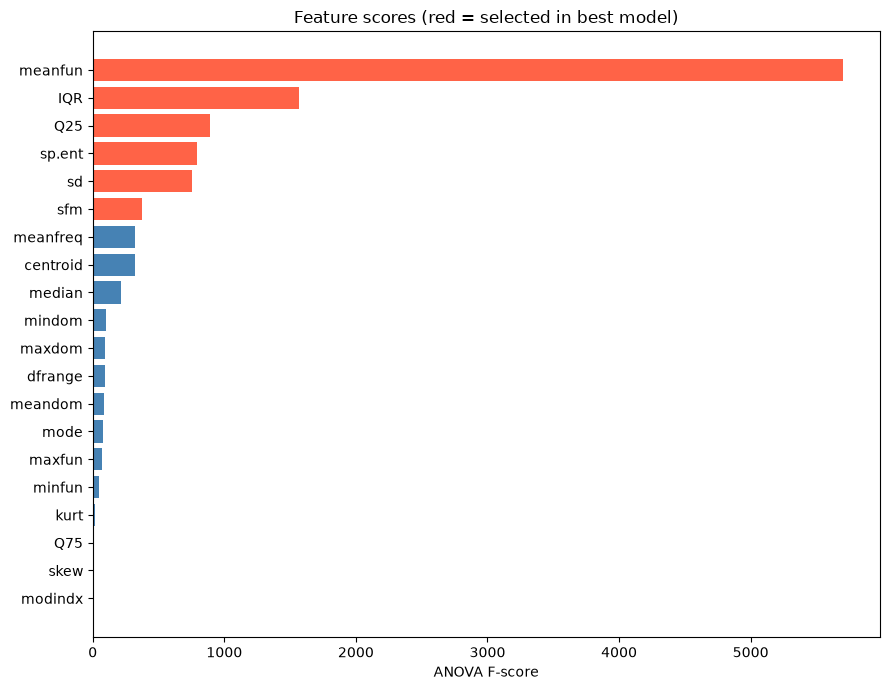

In [6]:
feature_scores = pd.DataFrame({
    "feature": X_train.columns,
    "score": selector.scores_,
    "selected": selector.get_support()
}).sort_values("score")

fig, ax = plt.subplots(figsize=(9, 7))
colors = ["tomato" if chosen else "steelblue"
        for chosen in feature_scores["selected"]]

ax.barh(feature_scores["feature"], feature_scores["score"], color=colors)
ax.set_xlabel("ANOVA F-score")
ax.set_title("Feature scores (red = selected in best model)")
plt.tight_layout()
plt.show()

Step 7 - Graph: test-set confusion matrix

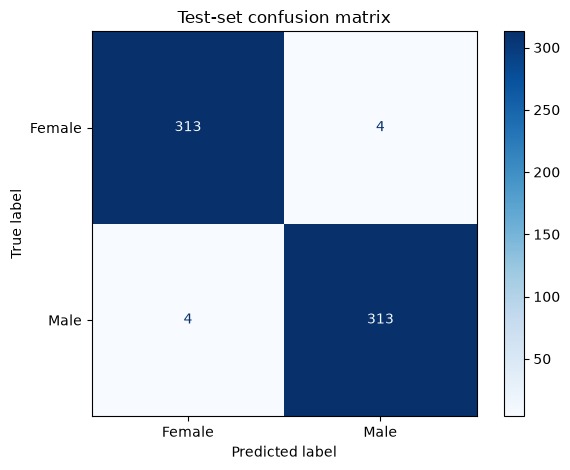

In [7]:
from sklearn.metrics import ConfusionMatrixDisplay

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    labels=["female", "male"],
    display_labels=["Female", "Male"],
    cmap="Blues"
)

plt.title("Test-set confusion matrix")
plt.tight_layout()
plt.show()

1. K-nearest neighbors model
I built a KNN classifier to predict whether a voice sample is male or female. The dataset contains 3,168 samples and 20 numeric voice features, with 1,584 samples in each class. I used an 80/20 stratified train-test split, scaled the features, and trained the model on the training data.

2. Feature selection
I compared feature subsets containing 1 to 20 features using five-fold stratified cross-validation. The features were ranked with an ANOVA F-test, and the subset with the highest mean cross-validation accuracy was selected. The selected features were: sd', 'Q25', 'IQR', 'sp.ent', 'sfm', 'meanfun.

3. Best value of k
I tested odd values of k from 1 to 31. The best value was k = 3, which gave a mean cross-validation accuracy of 0.9814494312822072. I then evaluated that model on the held-out test set, where it achieved 0.9873817034700315 accuracy. The heatmap compares the tested feature counts and k values; the confusion matrix shows the test-set predictions.